# task 2

In [60]:
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial import KDTree

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')
sns.set_context('notebook')

DATA_PATH = 'data/train_adata.h5ad'

adata = ad.read_h5ad(DATA_PATH)

print(f"Cells  (n_obs) : {adata.n_obs:,}")
print(f"Markers (n_vars): {adata.n_vars}")
print(f"Images          : {adata.obs['image'].nunique()}")


Cells  (n_obs) : 253,433
Markers (n_vars): 40
Images          : 132


In [61]:
max_val  = adata.layers['exprs'].max()
mean_val = adata.layers['exprs'].mean()

print("Checking transformation status of 'exprs' layer:")
print(f"  max  : {max_val:.3f}")
print(f"  mean : {mean_val:.3f}")
print()

if max_val < 15:
    print("CONCLUSION: 'exprs' is ALREADY arcsinh(x/5)-transformed.")
    print(f"  max ≈ {max_val:.1f}  →  raw counts up to sinh({max_val:.1f})×5 ≈ {np.sinh(max_val)*5:,.0f}")
    print("  Do NOT apply arcsinh again — that would double-transform the data.")
else:
    print("CONCLUSION: 'exprs' appears to be raw (max >> 15). Apply arcsinh(x/5).")

Checking transformation status of 'exprs' layer:
  max  : 8.436
  mean : 1.381

CONCLUSION: 'exprs' is ALREADY arcsinh(x/5)-transformed.
  max ≈ 8.4  →  raw counts up to sinh(8.4)×5 ≈ 11,526
  Do NOT apply arcsinh again — that would double-transform the data.


In [62]:
# here we get the column numbers of the cells
col = [np.where((adata.var['marker'] == f'{mark}') & (adata.var['use_channel'] == 1))[0][0] for mark in ['Ecad', 'CD8a', 'Ki67']]

# isolate the corrisponding data for each of the markers
values =[]
for i in col:
    values.append(adata.layers['exprs'][:,i])


/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before opera

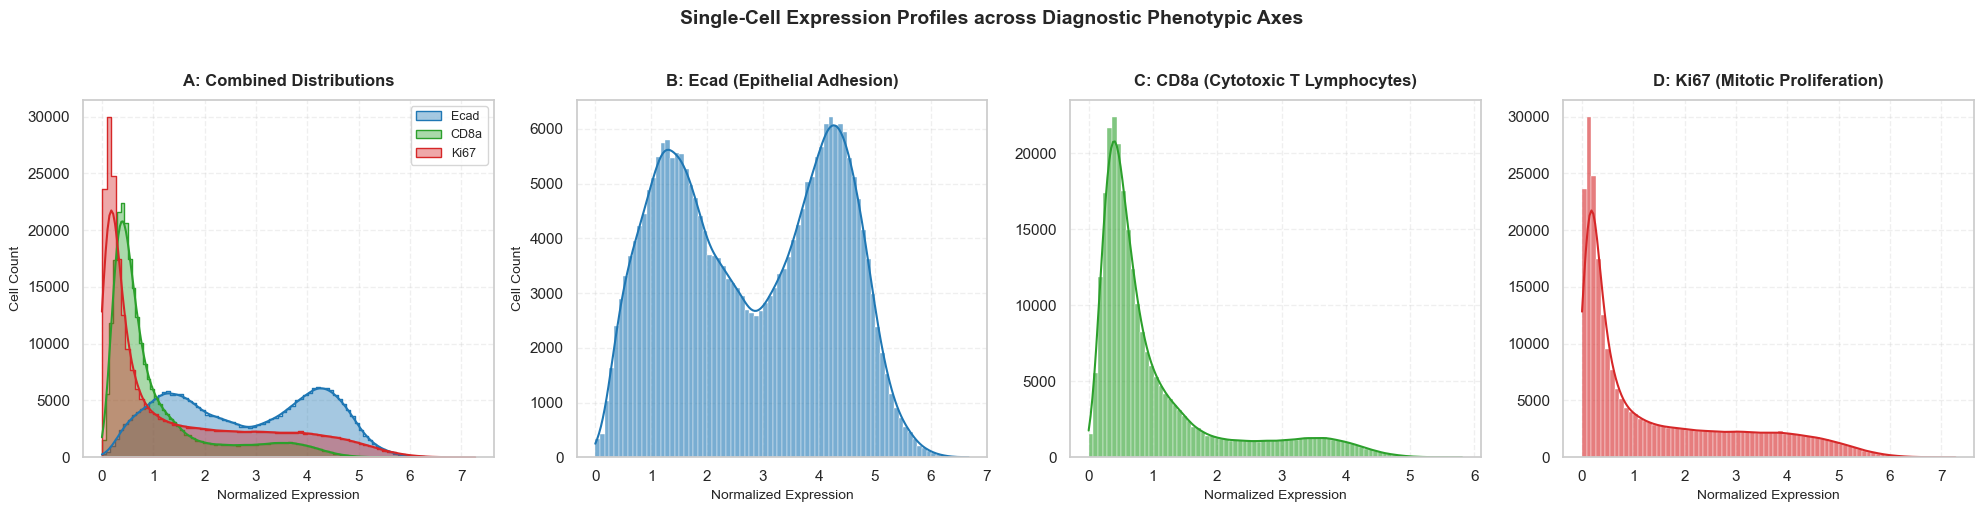

In [63]:
target_markers = ['Ecad', 'CD8a', 'Ki67']
palette = {'Ecad': '#1f77b4', 'CD8a': '#2ca02c', 'Ki67': '#d62728'}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for i, marker in enumerate(target_markers):
    sns.histplot(
        data=values[i], 
        bins=80, 
        label=marker, 
        kde=True, 
            # kde = kernel density estimation
        alpha=0.4, 
        color=palette[marker],
        ax=axes[0],
        element="step"
    )
axes[0].set_title('A: Combined Distributions', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Normalized Expression', fontsize=10)
axes[0].set_ylabel('Cell Count', fontsize=10)
axes[0].legend(loc='upper right', frameon=True, fontsize=9)
axes[0].grid(True, linestyle='--', alpha=0.3)

for i, marker in enumerate(target_markers):
    current_ax = axes[i + 1]
    
    sns.histplot(
        data=values[i], 
        bins=80, 
        kde=True, 
        alpha=0.6, 
        color=palette[marker],
        ax=current_ax,
        element="bars"
    )
    
    functional_labels = {'Ecad': 'Epithelial Adhesion', 'CD8a': 'Cytotoxic T Lymphocytes', 'Ki67': 'Mitotic Proliferation'}
    
    current_ax.set_title(f'{chr(66 + i)}: {marker} ({functional_labels[marker]})', fontsize=12, fontweight='bold', pad=10)
    current_ax.set_xlabel('Normalized Expression', fontsize=10)
    current_ax.set_ylabel('Cell Count' if i == 0 else '', fontsize=10)  # Reduce redundant axis titles
    current_ax.grid(True, linestyle='--', alpha=0.3)

# Layout optimization to prevent title/label clipping
plt.suptitle('Single-Cell Expression Profiles across Diagnostic Phenotypic Axes', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

Clearly we can see that the epithelial cells (Ecad) have a bimodal distribution, however we can't be sure of the other two.

In [64]:
# chaecking the distribution modality 

from scipy.stats import gaussian_kde
from scipy.signal import find_peaks
for i, marker in enumerate(['Ecad', 'CD8a', 'Ki67']):
    data=values[i]

    kde = gaussian_kde(data)

    x_grid = np.linspace(data.min(), data.max(), 1000)
    density = kde(x_grid)
    
    peaks, _ = find_peaks(density, distance=50, prominence=max(density)*0.02)
    # searches for local maxima
    
    is_bimodal = False
    num_peaks = len(peaks)
    
    if num_peaks >= 2:
        peaks = np.sort(peaks)
        
        region_pomiedzy = density[peaks[0]:peaks[1]]
        
        peak1_val = density[peaks[0]]
        peak2_val = density[peaks[1]]
        
        if np.min(region_pomiedzy) < (0.85 * min(peak1_val, peak2_val)):
            # okreslamy, ze w dystansie pomiedzy peak'ami wartosc musi byc mniejsza nic 85% nizszego peaka
            is_bimodal = True
        else:
            is_bimodal = False
    
    print(f"--- {marker} ---")
    print(f"  detected clear peaks: {num_peaks}")
    print(f"  bimodal? {is_bimodal}\n")

--- Ecad ---
  detected clear peaks: 2
  bimodal? True

--- CD8a ---
  detected clear peaks: 1
  bimodal? False

--- Ki67 ---
  detected clear peaks: 1
  bimodal? False



## interpretation
the distribution of single-cell expression reflects the phenotype of the the tissue:
- Ecad: distinct bimodal profile with two maxima observer, indicating a possibility of a binary population division: those with high-adhesion and low-adhesion epithelial cells. this coud be an indicator of the presence of seperate niches (one undergoing phenotypic transition where the other stays dormant)

- CD8a: a single, aasymetric peak = unimodal profile; indicates a highly specific marker, the right-handed shoulder indicated a subpopulation characterised by high expression wherein the majority of the cells display little to no expression (clustering around the 0-1 region). 

- Ki67: also a strongly right-skewed unimodal profile, with a dominant peak at low values indicating that the majority of cells stay in a quiescent state (G0 phase), where the right shoulder supports the presence of  mitotically active, growing tumor subsection

# Task 4 

## my chosen criterium is the the image that displayed the highest CD8/Tumor cell ratio 

In [65]:
plt.rcParams['figure.dpi'] = 100
sns.set_style('white')

In [66]:
adata.obsm['spatial'] = adata.obs[['Pos_X', 'Pos_Y']].values

print(f"Cells: {adata.n_obs:,}  |  Images: {adata.obs['image'].nunique()}")
print(f"Spatial coords shape: {adata.obsm['spatial'].shape}")
print(f"X range: [{adata.obs['Pos_X'].min():.1f}, {adata.obs['Pos_X'].max():.1f}] um")
print(f"Y range: [{adata.obs['Pos_Y'].min():.1f}, {adata.obs['Pos_Y'].max():.1f}] um")

Cells: 253,433  |  Images: 132
Spatial coords shape: (253433, 2)
X range: [0.0, 639.1] um
Y range: [0.3, 598.6] um


In [67]:

img_stats = adata.obs.groupby('image', observed=True).agg(
    n_cells=('Pos_X', 'count'),
    x_range=('Pos_X', lambda x: x.max() - x.min()),
    y_range=('Pos_Y', lambda x: x.max() - x.min()),
    indication=('Indication', 'first')
)

print("\nImages with most cells:")
print(img_stats.nlargest(5, 'n_cells')[['n_cells', 'indication']].to_string())


Images with most cells:
                                                                     n_cells indication
image                                                                                  
IMMUcan_Batch20210921_LUNG_10041543-LUNG-VAR-TIS-01-IMC-01_003.tiff     5152       THOR
IMMUcan_Batch20210921_UPSTREAM_S-210622-00014_004.tiff                  3746         HN
IMMUcan_Batch20210701_UPSTREAM_S-210510-00068_001.tiff                  3488         HN
IMMUcan_Batch20210304_10070084-SPECT-VAR-TIS-01-IMC-01_002.tiff         3439         GI
IMMUcan_Batch20210701_S-210531-00020_001.tiff                           3342      BREAS


In [68]:
image_counts = adata.obs.groupby(['image', 'cell_labels']).size().unstack(fill_value=0)

qualifying_images = image_counts[image_counts['Tumor'] >= 100].copy()

qualifying_images['cd8_tumor_ratio'] = qualifying_images['CD8'] / qualifying_images['Tumor']

image_id = qualifying_images['cd8_tumor_ratio'].idxmax()
image_value = qualifying_images.loc[image_id, 'cd8_tumor_ratio']

print(f"Image ID: {image_id}")
print(f"(CD8/Tumor Ratio): {image_value:.4f}")

Image ID: IMMUcan_Batch20210701_10075013-SPECT-VAR-TIS-UNST-03_002.tiff
(CD8/Tumor Ratio): 2.6138


/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/3993670696.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  image_counts = adata.obs.groupby(['image', 'cell_labels']).size().unstack(fill_value=0)


In [69]:
adata_img = adata[adata.obs['image'] == image_id].copy()
coords = adata_img.obsm['spatial']
coords

array([[8.85000000e+01, 4.00000000e-01],
       [2.45266667e+02, 4.66666667e-01],
       [1.03571429e+02, 1.20408163e+00],
       ...,
       [3.20272727e+02, 5.98227273e+02],
       [3.31312500e+02, 5.97781250e+02],
       [4.03444444e+02, 5.97944444e+02]])

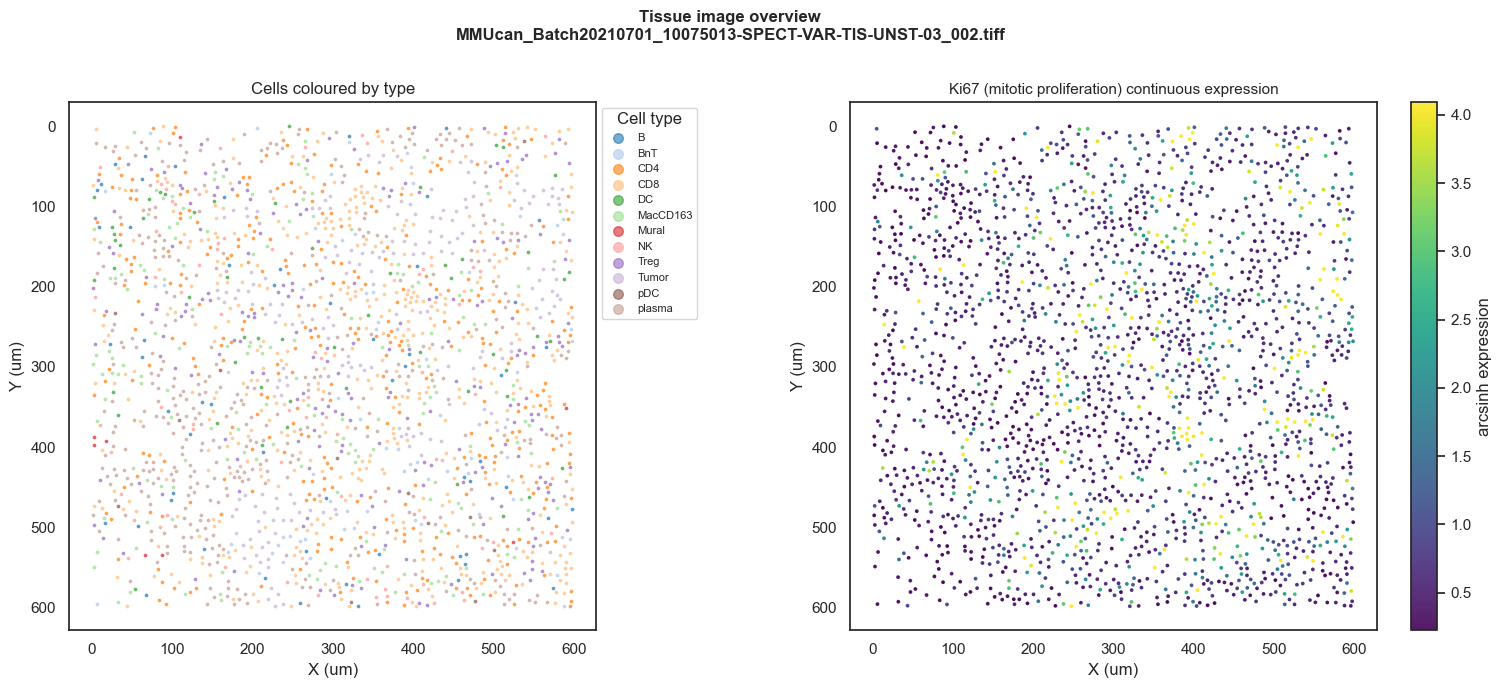

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

cell_types = sorted(adata_img.obs['celltypes'].unique())
palette = dict(zip(cell_types, sns.color_palette('tab20', len(cell_types))))

for ct in cell_types:
    c = coords[adata_img.obs['celltypes'] == ct]
    axes[0].scatter(c[:, 0], c[:, 1], s=3, alpha=0.6,
               color=palette[ct], label=ct, rasterized=True)

axes[0].set_aspect('equal')
axes[0].set_title('Cells coloured by type')
axes[0].set_xlabel('X (um)')
axes[0].set_ylabel('Y (um)')
axes[0].invert_yaxis()
axes[0].legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=8,
          markerscale=4, title='Cell type')

midx = np.where(adata_img.var['marker'] == 'Ki67')[0]
if len(midx) == 0:
    axes[1].text(0.5, 0.5, 'Ki67 not found', transform=axes[1].transAxes,
            ha='center', va='center')
else:
    expr = adata_img.layers['exprs'][:, midx[0]]
    sort_idx = np.argsort(expr)
    sc = axes[1].scatter(
        coords[sort_idx, 0], coords[sort_idx, 1],
        c=expr[sort_idx], cmap='viridis',
        s=3, alpha=0.9, rasterized=True,
        vmin=np.percentile(expr, 5), vmax=np.percentile(expr, 95)
    )
    plt.colorbar(sc, ax=axes[1], label='arcsinh expression')
    axes[1].set_aspect('equal')
    axes[1].invert_yaxis()
    axes[1].set_title('Ki67 (mitotic proliferation) continuous expression', fontsize=11)
    axes[1].set_xlabel('X (um)')
    axes[1].set_ylabel('Y (um)')

plt.suptitle(f"Tissue image overview\n{image_id[-60:]}\n",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

although we can see some overlap between the expression of Ki67 and the cell type, the signal is not prominent enough to deduce conclusions.

additional tests to showcaase the dstribution will be conducted: violin plot of the Ki67 expression over the cell types

/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/797581732.py:16: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  expression_stats = df_spatial.groupby('Cell Type')['Expression'].agg(['mean', 'median', 'std']).sort_values(by='mean', ascending=False)
/opt/anaconda3/lib/python3.11/site-packages/seaborn/categorical.py:641: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_vals = vals.groupby(grouper)


Quantified Expression Statistics per Cell Type:
               mean    median       std
Cell Type                              
pDC        1.992937  1.575212  1.441956
Tumor      1.834467  1.177991  1.557017
BnT        1.760047  1.212535  1.433403
Treg       1.184891  0.658297  1.240870
CD4        1.115767  0.688862  1.048691
CD8        1.104674  0.637955  1.118395
B          1.075268  0.744836  0.902345
plasma     1.048047  0.605950  1.102639
MacCD163   0.795736  0.480771  0.991604
NK         0.738540  0.503071  0.757126
DC         0.718315  0.443502  0.933468
Mural      0.377196  0.294169  0.297260


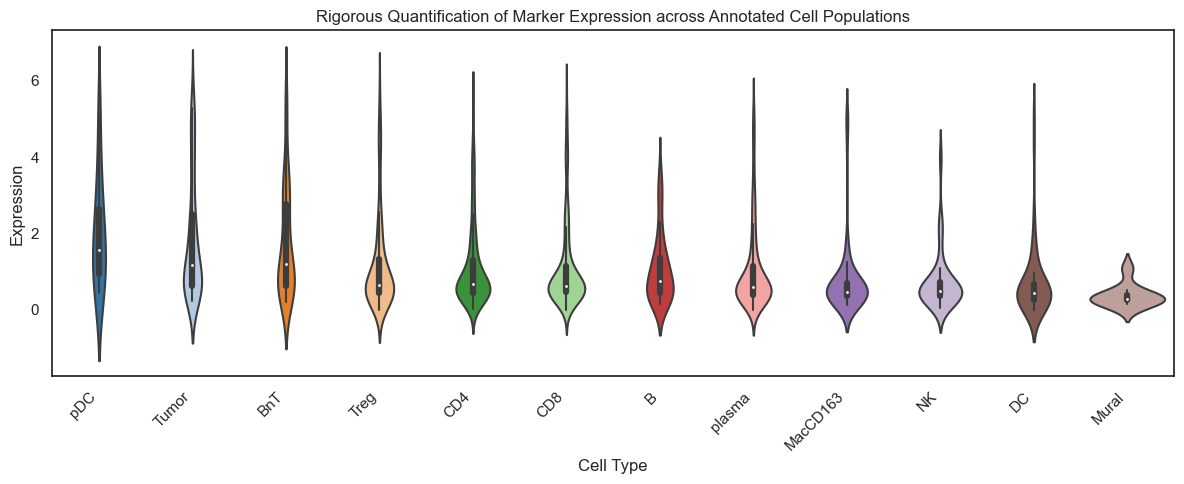

In [ ]:
midx = np.where(adata_img.var['marker'] == 'Ki67')[0][0]
marker_expr = adata_img.layers['exprs'][:, midx]

df_spatial = pd.DataFrame({
    'Cell Type': adata_img.obs['celltypes'],
    'Expression': marker_expr
})

expression_stats = df_spatial.groupby('Cell Type')['Expression'].agg(['mean', 'median', 'std']).sort_values(by='mean', ascending=False)
print("Quantified Expression Statistics per Cell Type:")
print(expression_stats)

plt.figure(figsize=(12, 5))
sns.violinplot(data=df_spatial, x='Cell Type', y='Expression', order=expression_stats.index, palette='tab20')
plt.xticks(rotation=45, ha='right')
plt.title('Rigorous Quantification of Marker Expression across Annotated Cell Populations')
plt.tight_layout()
plt.show()

as can be seen in this plot: the Ki67 marker cannot be assigned uniquely to one cell type.

### interpretation

the continuous expression of Ki67 isn't restricted to a specific phenotype. looking closer to the distrubution on the violin plot we observe, that it exhibits a widespread expression in the full range of cells - effectively refuting the notion that it is a purely tumor-restricted phenotype. 

# task 6

In [73]:
all_image_fractions = []
tumor_counts = []
    # lista liczby komorek nowotworowych w kolejntcg zdjeciach

grouped = adata.obs.groupby('image', observed=True)

for name, group in grouped:

    # print(f"Group: {name}")
    adata_img = adata[adata.obs['image'] == name].copy()

    coords = adata_img.obsm['spatial']
    cell_types = adata_img.obs['celltypes']

    tumor_coords = coords[adata_img.obs['celltypes'].values == 'Tumor']
    n_tumor_cells = tumor_coords.shape[0]

    if  n_tumor_cells == 0:
        print(f'{name} No  tumor cells for this image')
        continue

    tree = KDTree(coords)
    distances, idxs = tree.query(tumor_coords, k=11)
    neighbor_idxs = idxs[:, 1:].flatten()

    neighbor_types = cell_types.iloc[neighbor_idxs]
    image_fractions = neighbor_types.value_counts(normalize=True)

  
    image_fractions.name = name
    all_image_fractions.append(image_fractions)
    tumor_counts.append(n_tumor_cells)

fractions_df = pd.concat(all_image_fractions, axis=1).T.fillna(0.0)
    # laczymy dane z wszystkich zdjec

weights = np.array(tumor_counts)

weighted_means = np.average(fractions_df, axis=0, weights=weights)
    # srednia wazona

tumor_env = pd.Series(weighted_means, index=fractions_df.columns)

print(tumor_env)

IMMUcan_Batch20210506_10032400-GU-VAR-TIS-01-IMC-01_003.tiff No  tumor cells for this image
IMMUcan_Batch20210506_10068594-SPECT-VAR-TIS-01-IMC-01_003.tiff No  tumor cells for this image
IMMUcan_Batch20220309_10088313-SPECT-VAR-TIS-01-IMC-01_004.tiff No  tumor cells for this image
IMMUcan_Batch20220609_10089094-SPECT-VAR-TIS-01-IMC-01_001.tiff No  tumor cells for this image
IMMUcan_Batch20220908_10089829-SPECT-VAR-TIS-UNST-03_001.tiff No  tumor cells for this image
celltypes
Tumor         0.848316
Neutrophil    0.015659
CD8           0.034502
MacCD163      0.025559
DC            0.010142
CD4           0.014761
plasma        0.004496
NK            0.001505
Mural         0.024987
HLADR         0.008236
B             0.001315
Treg          0.008914
pDC           0.000584
BnT           0.001024
dtype: float64


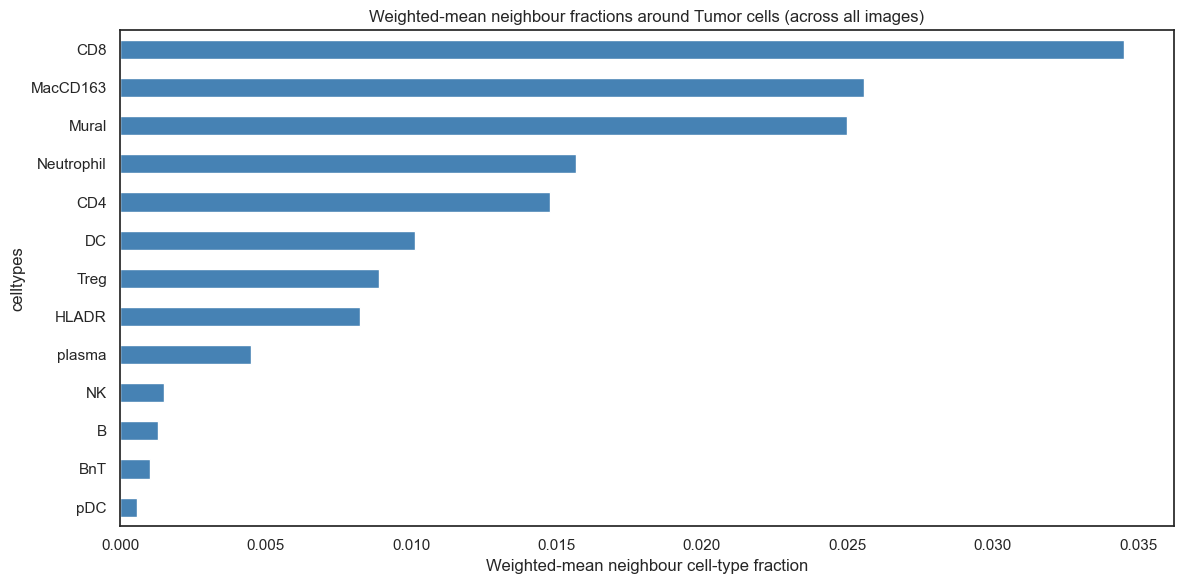

The non-Tumor cell type most frequently adjacent to Tumor cells is: CD8


In [74]:
non_tumor_env = tumor_env.drop('Tumor', errors='ignore').sort_values(ascending=False)

plt.figure(figsize=(12, 6))
non_tumor_env.plot(kind="barh", color="steelblue")
plt.xlabel("Weighted-mean neighbour cell-type fraction")
plt.title("Weighted-mean neighbour fractions around Tumor cells (across all images)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

if not non_tumor_env.empty:
    most_freq = non_tumor_env.index[0]
    print(f"The non-Tumor cell type most frequently adjacent to Tumor cells is: {most_freq}")
else:
    print("No non-Tumor cell types found adjacent to Tumor cells.")

the CD8 cells most frequently are present next to tumor cells. the CD8 is marker for the cytotoxic t cells. 

their abundant presence next to tumor cells indicates that in this image the tumor is being actively targetted by the immune system.

# task 7

the file chosen is the same as in task 4: IMMUcan_Batch20210701_10075013-SPECT-VAR-TIS-UNST-03_002.tiff

In [75]:
image_id

'IMMUcan_Batch20210701_10075013-SPECT-VAR-TIS-UNST-03_002.tiff'

In [76]:
adata_img = adata[adata.obs['image'] == image_id].copy()
adata_img.layers['exprs'].shape

(2080, 40)

In [82]:
tumor_cells = adata_img[adata_img.obs['cell_labels'] == 'Tumor'].copy()

possible markers to use :

1             HistoneH3
2                   SMA
3                  CD16
4                  CD38
6                  CD27
7                  CD15
11                 CD20
13                 Ido1
18               PDGFRb
20                 GrzB
25                 ICOS
28                 CD33
30                VISTA
31                 CD40
33                 CD14
35                CD303
36                CD206

34                 Ecad - epithelial cell adhesion; loss of ecad is an indicator of metastatic potential \
29                 Ki67 - assosiated with cellular proliferation; differentiates actively growing from passive cells \
37          cleavedPARP - segregates apoptotic or dying cell populations \
27    CarbonicAnhydrase - often upregulated in hypoxia enviroments; may indicate those populations that are resistant to radio or chemotherapy \
38                 DNA1 - staining dna? \
39                 DNA2 - staining dna? \

__________________________ \
12                 CD68 - identify tumor associated macrophages (tams) \
9                 CD163 - marker for immunosuppressive tams; high cd68/cd163 indicates poor prognosis \
16                CD11c - identifies dc populations \
5                 HLADR - mhc II marker; targets antugen-presenting cells (dc, b cells, activated t cells); lack signifies immune evasion \
0                   MPO - a neutrofil and granylocyte marker \
10                  B2M - mhc i marker; may indicate immune-evasive tumor subpopulations (loss od mhvc i populations)


____________________ \
17                  PD1 - programmed cell death \
21                 PDL1 - immune-checkpoint presenting cell populations
15                 LAG3 - \
32                  CD4 - helper t cells \
22                 TCF7 - tf marker; favourable prognosis on immune checkpoint blockade \
26                 CD8a - cytotoxic t cells \
24                FOXP3 - tf for regulatory t cells \ 
19                  CD7 - t cells and nk marker \
14                  CD3 - t cell marker \
8                CD45RA - naive or differentiated effector memoru t cells \
23               CD45RO - memory t cells \




_________________________ chosen ____________________ \
ecad, ki67, cleavedparp, carbonicanhydrase, b2m
cd3, cd8a - t cell infiltration
cd68, cd163 - macrophages
pdl1 



/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/169652130.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', k)


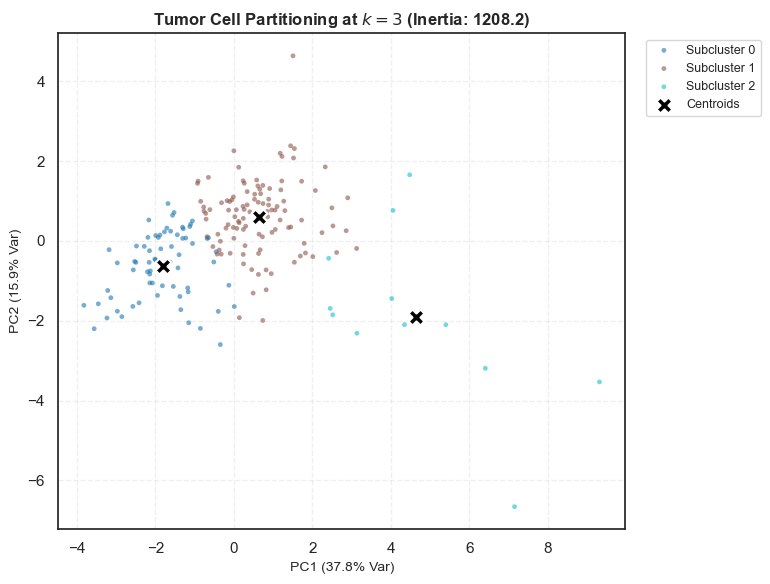

/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/169652130.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', k)


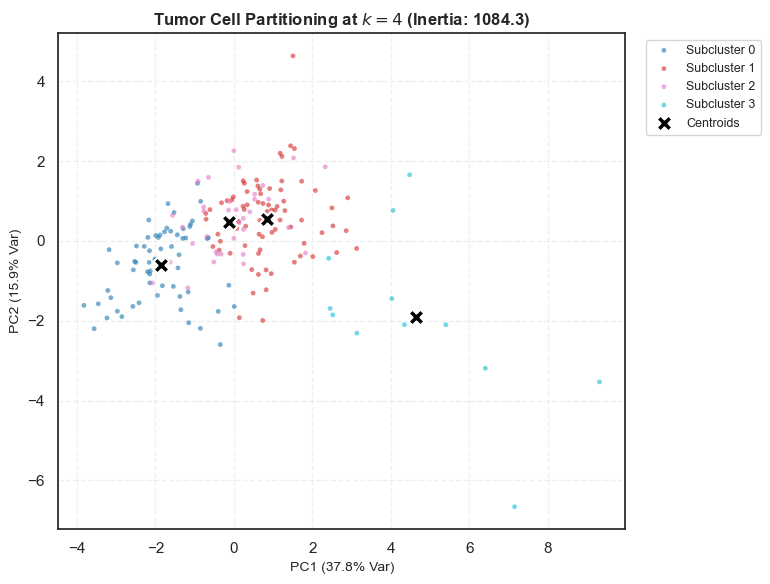

/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/169652130.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', k)


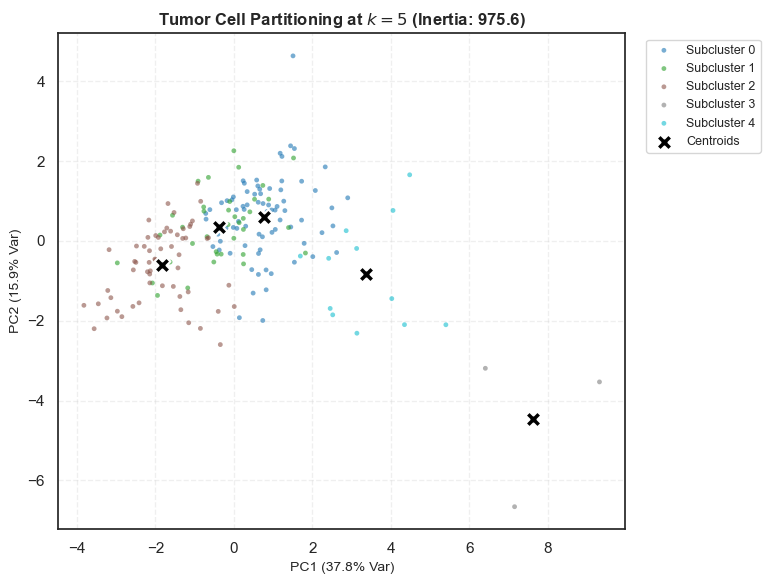

/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/169652130.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', k)


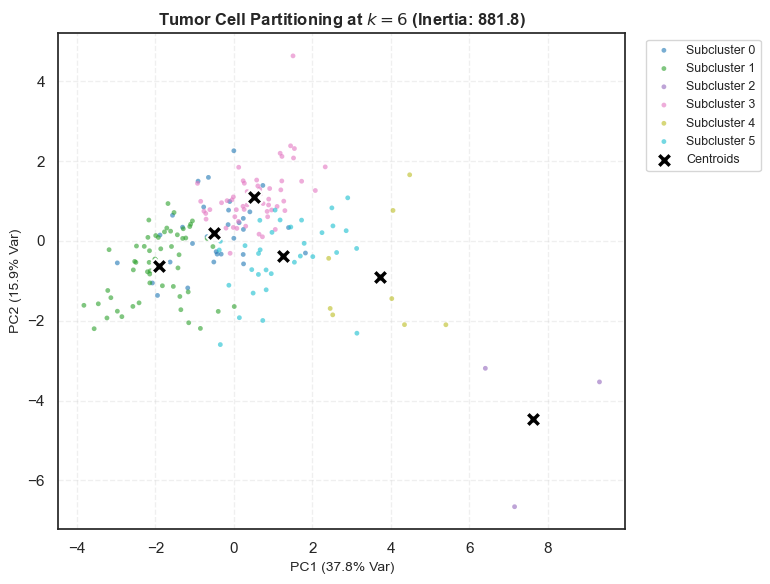

/var/folders/87/gnpzt0793j30jhjs037ckwtr0000gp/T/ipykernel_47952/169652130.py:35: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap('tab10', k)


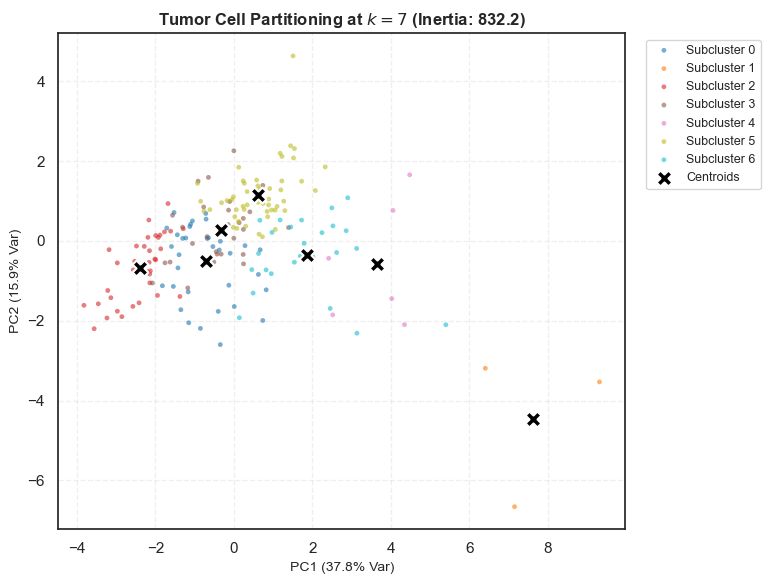

In [78]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
    # silkouette_score - computes the mean coefficient used to asses the qulity of an unsupervied clustering; how well separated the resulting clusters aka how tightly grouped they are

from sklearn.decomposition import PCA

marker_ids = [34, 29, 37, 27, 10, 14, 26, 12, 9, 21]

chosen_markers = tumor_cells.layers['exprs'][:, marker_ids]

scaler = StandardScaler()
normalised_markers = scaler.fit_transform(chosen_markers)

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(normalised_markers)
variance_explained = pca.explained_variance_ratio_ * 100

k_range = [3,4,5,6,7]

recorded_k = []
inertia_values = []
silhouette_values = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    cluster = kmeans.fit(normalised_markers)
    
    recorded_k.append(k)
    inertia_values.append(cluster.inertia_)
    silhouette_values.append(silhouette_score(normalised_markers, cluster.labels_, metric='euclidean'))

    plt.figure(figsize=(8, 6))
    
    cmap = plt.cm.get_cmap('tab10', k)
    
    for cluster_idx in range(k):
        mask = (cluster.labels_ == cluster_idx)
        plt.scatter(
            X_pca[mask, 0], 
            X_pca[mask, 1], 
            s=12, 
            color=cmap(cluster_idx),
            label=f'Subcluster {cluster_idx}',
            alpha=0.6,
            edgecolors='none'
        )
        
    centroids_pca = pca.transform(kmeans.cluster_centers_)
    plt.scatter(
        centroids_pca[:, 0], 
        centroids_pca[:, 1], 
        s=130, 
        marker='X', 
        color='black', 
        edgecolors='white', 
        linewidth=1.5, 
        label='Centroids'
    )
    
    plt.title(f'Tumor Cell Partitioning at $k = {k}$ (Inertia: {kmeans.inertia_:.1f})', fontsize=12, fontweight='bold')
    plt.xlabel(f'PC1 ({variance_explained[0]:.1f}% Var)', fontsize=10)
    plt.ylabel(f'PC2 ({variance_explained[1]:.1f}% Var)', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.3)
    plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1), frameon=True, fontsize=9)
    plt.tight_layout()
    
    plt.show()


kmeans_df = pd.DataFrame({
    'k': recorded_k,
    'inertia': inertia_values,
    'silhouette_score': silhouette_values
})


### plotting the inertia to choose the best k

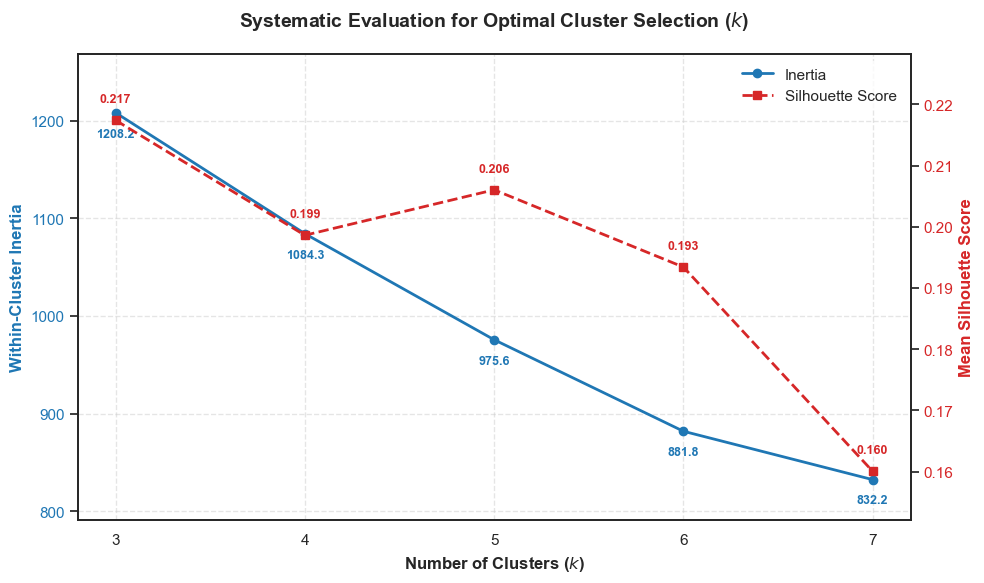

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 6))

color_inertia = '#1f77b4'  # Deep Blue
ax1.set_xlabel('Number of Clusters ($k$)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Within-Cluster Inertia', color=color_inertia, fontsize=12, fontweight='bold')
line1 = ax1.plot(kmeans_df['k'], kmeans_df['inertia'], marker='o', linestyle='-', color=color_inertia, linewidth=2, label='Inertia')
ax1.tick_params(axis='y', labelcolor=color_inertia)
ax1.grid(True, linestyle='--', alpha=0.5)

for x, y in zip(kmeans_df['k'], kmeans_df['inertia']):
    ax1.annotate(
        f'{y:.1f}',              
        xy=(x, y), 
        xytext=(0, -15),         
        textcoords='offset points', 
        ha='center',             
        va='center', 
        fontsize=9, 
        color=color_inertia, 
        fontweight='bold'
    )

ax2 = ax1.twinx()
color_silhouette = '#d62728'  
ax2.set_ylabel('Mean Silhouette Score', color=color_silhouette, fontsize=12, fontweight='bold')
line2 = ax2.plot(kmeans_df['k'], kmeans_df['silhouette_score'], marker='s', linestyle='--', color=color_silhouette, linewidth=2, label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color_silhouette)

for x, y in zip(kmeans_df['k'], kmeans_df['silhouette_score']):
    ax2.annotate(
        f'{y:.3f}',           
        xy=(x, y), 
        xytext=(0, 15),       
        textcoords='offset points', 
        ha='center', 
        va='center', 
        fontsize=9, 
        color=color_silhouette, 
        fontweight='bold'
    )

plt.xticks(k_range)

ax1.set_ylim(kmeans_df['inertia'].min() * 0.95, kmeans_df['inertia'].max() * 1.05)
ax2.set_ylim(kmeans_df['silhouette_score'].min() * 0.95, kmeans_df['silhouette_score'].max() * 1.05)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', frameon=True, facecolor='white', edgecolor='none')

plt.title('Systematic Evaluation for Optimal Cluster Selection ($k$)', fontsize=14, fontweight='bold', pad=20)
fig.tight_layout()

plt.show()

In [80]:

for idx in range(5):
    if idx == 4:
        break
    print(f"delta{idx+1} between {idx+3} and {idx+4}: {kmeans_df['inertia'][idx] - kmeans_df['inertia'][idx+1]}")


delta1 between 3 and 4: 123.93214284819214
delta2 between 4 and 5: 108.6845924734721
delta3 between 5 and 6: 93.76986117543629
delta4 between 6 and 7: 49.59053464651538


mathematically the best would be k=5, as the silhouette score is the highest, indicating optimal cluster separation. 

howeveer by analysing the rate of change in within-cluster inertia it can be seen that the most substantial compression of data occurs when when transitioning from 3 to 4 clusters.  

additionally the PCA projections confirms that moving to k=5 or k=6 merely fragments the core cellular density into arbitrary subdivisions rather than resolving isolated topologies.

the unsupervised algorithm may align with the four foundational axes of tumor heterogeneity: proliferation (Ki67), hypoxia (CarbonicAnhydrase), epithelial-mesenchymal transition (Ecad,SMA), and apoptosis (cleavedPARP).




In [83]:
# saving the chosen clustering for task 8
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
cluster = kmeans.fit(normalised_markers)
tumor_cells.obs['optimal_clusters'] = cluster.labels_

# task 8

In [52]:
#wyizolowac usable markers
usable_markers = tumor_cells[:, tumor_cells.var['use_channel'] == 1]

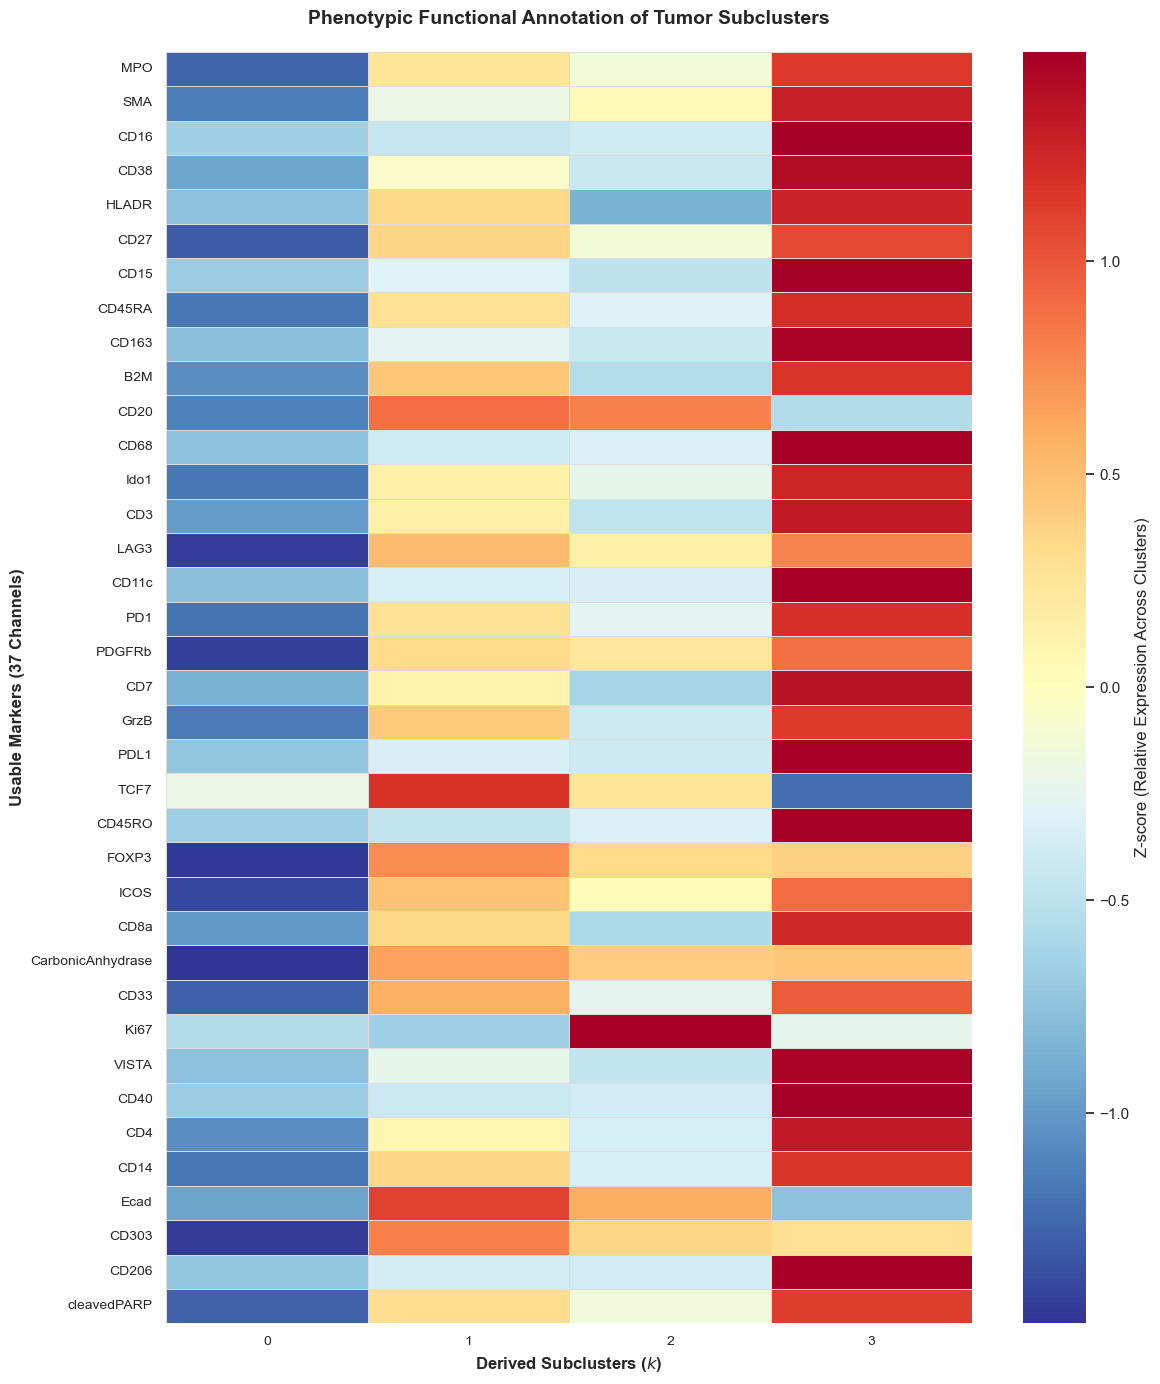

In [ ]:
expression_matrix = usable_markers.layers['exprs']
marker_names = usable_markers.var['marker']
cluster_labels = usable_markers.obs['optimal_clusters'].values

df_exprs = pd.DataFrame(expression_matrix, columns=marker_names)
df_exprs['Cluster'] = cluster_labels

cluster_profiles = df_exprs.groupby('Cluster').mean().T

#the sns.heatmap doesnt have a z-score option, so i will manually compute the normalisation
row_means = cluster_profiles.mean(axis=1)
row_stds = cluster_profiles.std(axis=1)

epsilon = 1e-6
cluster_profiles_normalized = cluster_profiles.sub(row_means, axis=0).div(row_stds + epsilon, axis=0)

plt.figure(figsize=(12, 14))

sns.heatmap(
    cluster_profiles_normalized, 
    cmap='RdYlBu_r', 
    cbar_kws={'label': 'Z-score (Relative Expression Across Clusters)'},
    linewidths=0.5,
    linecolor='gainsboro'
)

plt.title('Phenotypic Functional Annotation of Tumor Subclusters', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Derived Subclusters ($k$)', fontsize=12, fontweight='bold')
plt.ylabel('Usable Markers (37 Channels)', fontsize=12, fontweight='bold')
plt.tick_params(axis='both', labelsize=10)

plt.tight_layout()
plt.show()

## proposed biological explanation of each cluster
- cluster 0: 
    - we can see a global downregulation of almost all functional markers; 
    - low levels of Ki67 (here: signifies not actively proliferating cells), CarbonicAnhydrase (here: the cells do not experience hypoxia), FOXP3 (here: absence of regulatory T-cell signals), ICOS (here: cells are immunologically silent) 
    - these cells are functionally non-responsive, metabolically inactive, unengaged by the surrounding enviroment; 
    - summary: this niche captures a stable reservoir of the tumor mass that is dormant, showing no signs of proliferative expansion, hypoxic stress, or active immune interaction;

    - **non-reactive epithelial niche**



- cluster 1: 
    - noticable upregulation of TCF7 (a tf crucial for maintaining stemness; implies the enabaling self-renewal processes and high cellular plasticity), CD20 (indicates spatial proximity with localized humoral immune aggregates), Ecad (retaining epithelial phenotype)
    - summary: these cells maintain epithelial phenotype yet show activation of transformation into stem-like cells with unlimited proliferation capacity directed for expansion or structural remodeling; 

    - **EMT niche**

- cluster 2: 
    -  almost exclusively defined by the intense upregulation of Ki67 (here: rapid proliferation, highly mitotic growing cells); 
    - overall downregulation of the markers (like HLADR - here: signifies active immune evasion, CD8a - here: lack of infiltrating cytotoxic T cells),
    - alongside supporting upregulation of CD20 (here: physical proximity or signal leakage from neighboring B-cells) and Ecad (here: strong retention of the cohesive epithelial architecture);
    - summary: these cells represent the rapidly expanding core of the tumor mass, maximizing mitotic activity while excluding active cellular immunity and maintaining baseline epithelial cohesion;

    - **highly-proliferative niche**


- cluster 3: 
    - the most intensively upregulated cluster of all; 
    - heavily enriched for macrophage lineage markers (CD14, CD68, CD16, CD163, CD206), antigen-presenting molecules (HLADR, B2M), immune checkpoints (PDL1, Ido1, VISTA, PD1, LAG3), and T-cell markers (CD3, CD4, CD8a), 
    - also shows the highest enrichment for cleavedPARP (here: explicitly denoting the activation of terminal programmed cell death pathways within these cells)
    - summary: this niche is a highly inflamed hotspot where tumor cells are under immune attack undergoing terminal apoptotic stress;
    
    - **immune-reactive, dying tumor cells**
